# Vórtices puntuales 2D como sistema hamiltoniano (prototipo)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter, FFMpegWriter
from IPython.display import HTML

## Ecuaciones de movimiento y RK4

In [2]:
def U(posx, posy, gamma):
    # Función para calcular la velocidad de cada vórtice puntual
    # posx: array que contiene la posicion en x de cada vortice puntual
    # posy: array que contiene la posicion en y de cada vortice puntual
    # gamma: array que contiene la constante de circulación de cada vórtice
    # out: tupla que contiene los array de las velocidades de cada vórtice
    dx = posx[:, None] - posx[None, :] # x_i - x_j (crea matrices antisimétricas)
    dy = posy[:, None] - posy[None, :] # y_i - y_j (crea matrices antisimétricas)
    S = dx**2 + dy**2
    np.fill_diagonal(S, np.inf)
    inv_S = 1.0 / S # No calcula la inversa de S, solo la inversa de cada componente

    u = -1/(2*np.pi) * (dy * inv_S) @ gamma 
    v = 1/(2*np.pi) * (dx * inv_S) @ gamma
    return u, v

def Hamiltoniano(posx,posy,gamma):
    # Función para calcular el hamiltoniano
    # posx: array que contiene la posicion en x de cada vortice puntual
    # posy: array que contiene la posicion en y de cada vortice puntual
    # gamma: array que contiene la constante de circulación de cada vórtice
    # out: float con el valor del hamiltoniano
    dx = posx[:, None] - posx[None, :]
    dy = posy[:, None] - posy[None, :]
    nu = np.sqrt(dx**2 + dy**2)
    np.fill_diagonal(nu,1)
    return -1/(8*np.pi)* gamma @ np.log(nu) @ gamma

def int_movimiento(posx,posy,gamma):
    # Función para calcular las integrales de movimiento: componentes del momentum lineal y momentum angular
    # posx: array que contiene la posicion en x de cada vortice puntual
    # posy: array que contiene la posicion en y de cada vortice puntual
    # gamma: array que contiene la constante de circulación de cada vórtice
    # out: tupla de floats con el valor de cada integral de movimiento
    Q = np.sum(gamma*posx)
    P = np.sum(gamma*posy)
    I = np.sum(gamma*(posx**2 + posy**2))
    return  Q, P, I
    

def Ufield(xmesh, ymesh, posx, posy, gamma):
    # Función para calcular las componenetes del campo de velocidades de manera general
    # xmesh: matriz con los valores de x del espacio discreto
    # ymesh: matriz con los valores de y del espacio discreto
    # posx: array que contiene la posicion en x de cada vortice puntual
    # posy: array que contiene la posicion en y de cada vortice puntual
    # gamma: array que contiene la constante de circulación de cada vórtice
    # out: tupla que contiene los array de las velocidades de cada vórtice
    u = np.zeros_like(xmesh)
    v = np.zeros_like(ymesh)
    for i in range(len(posx)):
        dx = xmesh - posx[i]
        dy = ymesh - posy[i]
        s = dx**2 + dy**2
        s[s < 1e-12] = np.inf          # evita 1/0 si la malla cae sobre un vórtice
        u += -gamma[i] * dy / s / (2*np.pi)
        v +=  gamma[i] * dx / s / (2*np.pi)
    return u, v



def animar(x, y, gamma, Ufield=None, t=None, campo='quiver', n_malla=25, estela=200, salto=5, 
           intervalo=30, guardar=None, fps=30, dpi=100):
    # Función que realiza la animación del movimiento de los vórtices puntuales junto con el campo de velocidades.
    #
    # x, y:      arrays (N, n) con la posición de cada vórtice (fila) en cada paso (columna)
    # gamma:     array (N) con las circulaciones
    # Ufield:    función que calcula el campo de velocidades
    # t:         array (n,) con los tiempos (opcional, para mostrar t en pantalla)
    # campo:     'quiver' (flechas, rápido), 'stream' (líneas de corriente, más lento) o None (solo los vórtices)
    # n_malla:   número de puntos por lado de la malla cuadrada del campo
    # estela:    pasos de trayectoria que se dibujan detrás de cada vórtice
    # salto:     se dibuja un cuadro cada 'salto' pasos de la simulación
    # intervalo: milisegundos entre cuadros
    # guardar:   nombre de archivo (ej. 'vortices.gif'); None para no guardar
    # fps:       cuadros por segundo del archivo guardado
    # dpi:       int con el número de puntos para la imagen, es la resolución del video.

    N, n = x.shape
    gamma = np.asarray(gamma, dtype=float)
    colores = np.where(gamma > 0, 'tab:red', np.where(gamma < 0, 'tab:blue', 'gray'))

    # Límites y malla cuadrados: el mismo rango para x e y
    margen = 0.1 * max(np.ptp(x), np.ptp(y), 1.0)
    lo = min(x.min(), y.min()) - margen
    hi = max(x.max(), y.max()) + margen
    eje = np.linspace(lo, hi, n_malla)
    X, Y = np.meshgrid(eje, eje)

    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

    def campo_en(f):
        """Campo (u, v) y su rapidez en el paso f."""
        u, v = Ufield(X, Y, x[:, f], y[:, f], gamma)
        rap = np.maximum(np.hypot(u, v), 1e-12)   # evita dividir entre cero
        return u, v, rap

    # --- Campo inicial ---
    flechas = None
    corriente = None
    if campo is not None:
        u, v, rap = campo_en(0)
        logr = np.log10(rap)
        # Escala de color fija (en log10 de la rapidez) para que no parpadee
        clim = (np.percentile(logr, 5), np.percentile(logr, 95))
        if campo == 'quiver':
            flechas = ax.quiver(X, Y, u / rap, v / rap, logr, pivot='mid',
                                cmap='viridis', clim=clim, alpha=0.8, zorder=1)
        else:
            corriente = ax.streamplot(X, Y, u, v, density=1.5, linewidth=0.7,
                                      color='gray', arrowsize=0.8)
    else:
        ax.grid(True, alpha=0.3)

    puntos = ax.scatter(x[:, 0], y[:, 0], c=colores, s=60, zorder=3,
                        edgecolors='k', linewidths=0.5)
    lineas = [ax.plot([], [], color=colores[k], lw=0.8, alpha=0.7, zorder=2)[0]
              for k in range(N)]
    texto = ax.text(0.02, 0.96, '', transform=ax.transAxes, va='top',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

    def actualizar(f):
        nonlocal corriente
        puntos.set_offsets(np.column_stack((x[:, f], y[:, f])))
        ini = max(0, f - estela)
        for k, linea in enumerate(lineas):
            linea.set_data(x[k, ini:f + 1], y[k, ini:f + 1])
        if t is not None:
            texto.set_text(f't = {t[f]:.2f}')

        artistas = [puntos, *lineas, texto]
        if campo is not None:
            u, v, rap = campo_en(f)
            if campo == 'quiver':
                flechas.set_UVC(u / rap, v / rap, np.log10(rap))
                artistas.append(flechas)
            else:
                # streamplot no se puede actualizar: se borra y se vuelve a dibujar
                corriente.lines.remove()
                for p in list(ax.patches):
                    p.remove()
                corriente = ax.streamplot(X, Y, u, v, density=1.5, linewidth=0.7,
                                          color='gray', arrowsize=0.8)
        return artistas

    anim = FuncAnimation(fig, actualizar, frames=range(0, n, salto),
                         interval=intervalo, blit=(campo != 'stream'))

    if guardar is not None:
        ext = guardar.lower().rsplit('.', 1)[-1]
        if ext == 'mp4':
            if not FFMpegWriter.isAvailable():
                raise RuntimeError("No se encontró ffmpeg: instálalo o usa imageio-ffmpeg "
                                   "(ver el docstring de animar)")
            escritor = FFMpegWriter(fps=fps, bitrate=2000)
        elif ext == 'gif':
            escritor = PillowWriter(fps=fps)
        else:
            raise ValueError("guardar debe terminar en .mp4 o .gif")
        anim.save(guardar, writer=escritor, dpi=dpi)


    
    return anim

# Pámetros del sistema

In [3]:
h = 0.01 # (s) salto temporal
tf = 120 # (s) tiempo total de la simulación

# Caso N=2

p0 = np.array([[-0.5, 0.5], 
               [0.5, -0.5]])
gamma = np.array([1.0,
                -3.0])

# Caso N=3
'''
p0 = np.array([[-0.8, -0.3], 
               [1.0, 0.4], 
               [-0.3, 0.8]])
gamma = np.array([-3.5,
                  3.0,
                  -2.0])
'''
# Caso N=4
'''
p0 = np.array([[-0.5, -0.3], 
               [0.4, -0.4], 
               [0.5, 0.6],
               [-0.2, 0.3]])
gamma = np.array([-1.0,
                  2.0,
                  -3.0,
                  4.0])
'''

'\np0 = np.array([[-0.5, -0.3], \n               [0.4, -0.4], \n               [0.5, 0.6],\n               [-0.2, 0.3]])\ngamma = np.array([-1.0,\n                  2.0,\n                  -3.0,\n                  4.0])\n'

In [4]:
n = int(tf/h) # número de pasos total
N = np.size(p0[:,0]) # número de vórtices


# Incializo donde se  guardan las posiciones de cada vórtice, son matrices de Nxn, las filas 
# son el vortice y las columnas el paso
x = np.zeros((N,n), dtype=float)
y = np.zeros((N,n), dtype=float)


# Agrega el valor inicial de la posición de cada vóritce en los vectores de las posiciones
for i in range(0,N):
    x[i,0] = p0[i,0]
    y[i,0] = p0[i,1]

# Evolución temporal con integración de RK4
for i in range(0,n-1):
    kx1, ky1 = U(x[:,i], y[:,i], gamma)
    kx2, ky2 = U(x[:,i] + 0.5*h*kx1, y[:,i] + 0.5*h*ky1, gamma)
    kx3, ky3 = U(x[:,i] + 0.5*h*kx2, y[:,i] + 0.5*h*ky2, gamma)
    kx4, ky4 = U(x[:,i] + h*kx3, y[:,i] + h*ky3,gamma)
    x[:,i+1] = x[:,i] + (h/6)*(kx1 + 2*kx2 + 2*kx3 + kx4)
    y[:,i+1] = y[:,i] + (h/6)*(ky1 + 2*ky2 + 2*ky3 + ky4)

# Verificación de cantidades conservadas

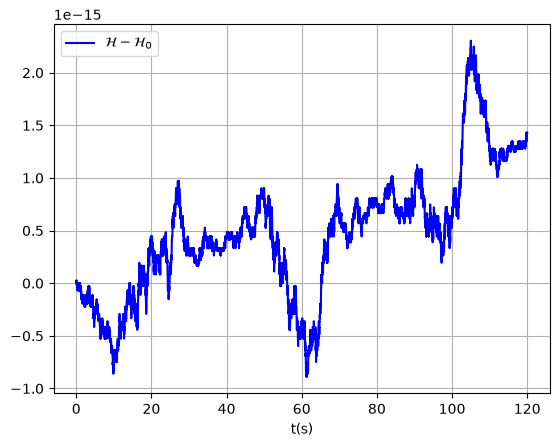

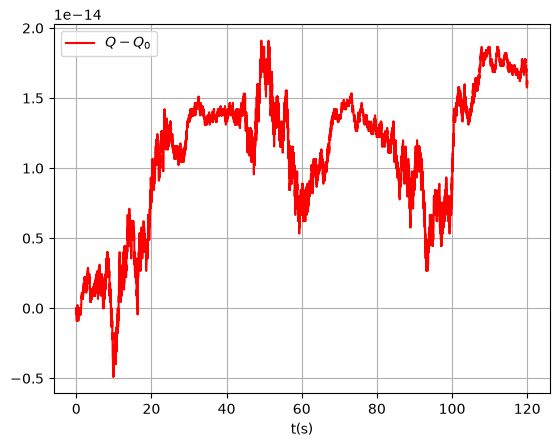

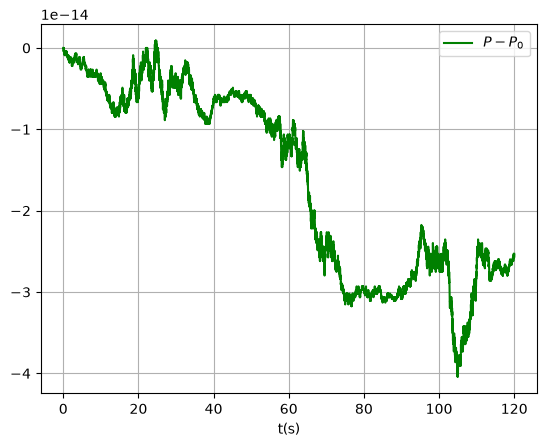

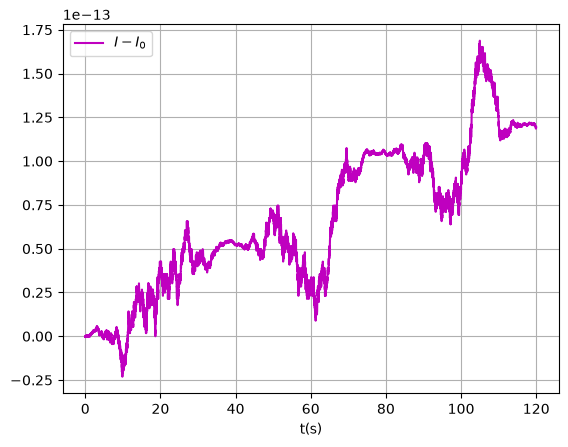

In [5]:
t = np.arange(0,tf,h)
path = f'Graficas_N{N}/'
H = [Hamiltoniano(x[:,i],y[:,i],gamma) for i in range(0,n)]
Q = [int_movimiento(x[:,i],y[:,i],gamma)[0] for i in range(0,n)]
P = [int_movimiento(x[:,i],y[:,i],gamma)[1] for i in range(0,n)]
I = [int_movimiento(x[:,i],y[:,i],gamma)[2] for i in range(0,n)]

plt.plot(t,H-H[0], 'b',label=r'$\mathcal{H}-\mathcal{H}_0$')
plt.xlabel('t(s)')
plt.legend()
plt.grid()
#plt.savefig(f'{path}N{N}_H.pdf')
plt.show()

plt.plot(t,Q-Q[0], 'r',label=r'$Q-Q_0$')
plt.xlabel('t(s)')
plt.legend()
plt.grid()
#plt.savefig(f'{path}N{N}_Q.pdf')
plt.show()

plt.plot(t,P-P[0], 'g',label=r'$P-P_0$')
plt.xlabel('t(s)')
plt.legend()
plt.grid()
#plt.savefig(f'{path}N{N}_P.pdf')
plt.show()

plt.plot(t,I-I[0], 'm',label=r'$I-I_0$')
plt.xlabel('t(s)')
plt.legend()
plt.grid()
#plt.savefig(f'{path}N{N}_I.pdf')
plt.show()

# Animación

Animation size has reached 21078995 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


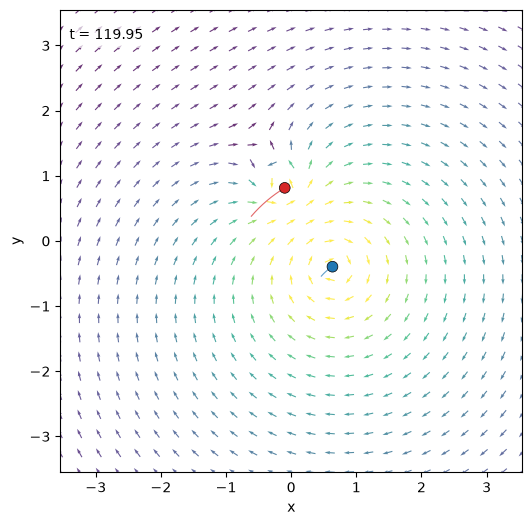

In [6]:
#anim = animar(x, y, gamma, Ufield, t=t, campo='quiver', n_malla=25, salto=5, guardar=f'videoN{N}.mp4', dpi=500)
anim = animar(x, y, gamma, Ufield, t=t, campo='quiver', n_malla=25, salto=5, dpi=500)
HTML(anim.to_jshtml())